# Análise Exploratória de Churn — Plataforma de Streaming

**Autor:** Brenno Azevedo · [LinkedIn](https://www.linkedin.com/in/) · [GitHub](https://github.com/brenno-azevedo)
**Contexto:** Projeto da disciplina *Dados, IA e Negócio* — Pós-graduação em Data Science e IA (UNIPDS/Anhanguera)

---

## O problema de negócio

A diretoria de uma plataforma de cursos por assinatura desconfia que o cancelamento
piorou e ninguém sabe explicar por quê. Foi entregue um extrato de 5.025 clientes,
exportado às pressas de três sistemas diferentes — portanto com inconsistências reais.

Antes de qualquer modelo, a pergunta é mais básica: **o que existe nesse dado, o que
está errado nele, e o que ele já responde sem modelagem nenhuma.**

## O que este notebook faz

1. **Análise univariada e limpeza** — tipos, ausentes, cardinalidade, padronização de
   categorias, consistência lógica entre datas e tratamento de outliers por tipo.
2. **Engenharia de atributos** — criação de `recencia`, `meses_assinatura` e `receita_acumulada`.
3. **Análise bivariada** — relação de cada variável com o churn, sobre uma base filtrada
   por maturidade mínima.
4. **Quatro frameworks de decisão** — coorte de retenção, RFM, Pareto dos motivos de
   cancelamento e funil de onboarding.

## Sobre os dados

A base é **sintética**, fornecida pelo curso para fins didáticos. Nenhuma informação real
de cliente é usada ou distribuída neste repositório — os arquivos são lidos diretamente
do repositório público da instituição, o que mantém o notebook reprodutível sem publicar
dado algum aqui.

| Arquivo | Conteúdo |
|---|---|
| `clientes_base.csv` | 5.025 assinantes, 16 colunas |
| `funil_eventos.csv` | 12.886 eventos de onboarding |

---
## 1. Carregamento e primeira inspeção

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
# Resolucao moderada: mantem os graficos legiveis e o .ipynb leve o bastante
# para o GitHub renderizar a pagina sem truncar.
plt.rcParams["figure.dpi"] = 72

# Os dados vêm do repositório público do curso. Para rodar com uma cópia local,
# basta apontar BASE_DADOS para a sua pasta.
BASE_DADOS = ("https://raw.githubusercontent.com/unipds-ciencia-de-dados/ciencia-de-dados/"
              "main/disciplina-01-dados-ia-negocios/disc01-mod03-aula03")

df = pd.read_csv(f"{BASE_DADOS}/clientes_base.csv")
print(f"Base carregada: {df.shape[0]} linhas e {df.shape[1]} colunas")

Base carregada: 5025 linhas e 16 colunas


In [2]:
# Exibir as primeiras linhas do DataFrame
if 'df' in locals():
    display(df.head())

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0


In [3]:
# Exibir informações sobre as colunas e seus tipos de dados
if 'df' in locals():
    print("\nTipos das colunas do DataFrame:")
    display(df.dtypes)


Tipos das colunas do DataFrame:


cliente_id                  int64
idade                       int64
plano                         str
ciclo                         str
valor_mensal              float64
regiao                        str
canal_aquisicao               str
nps                         int64
data_assinatura               str
data_cancelamento             str
data_ultimo_acesso            str
data_extracao                 str
dias_ativos_ult_mes         int64
horas_assistidas_total    float64
motivo_cancelamento           str
churn                       int64
dtype: object

### Análise de Valores Únicos e Gráficos de Barra
Análise de frequência para as colunas: `plano`, `ciclo`, `regiao` e `canal_aquisicao`.


--- Contagem para a coluna: plano ---
plano
Basico     708
BASICO     677
básico     677
Padrao     665
Padrão     654
padrão     646
premium    513
Premium    485
Name: count, dtype: int64

--- Contagem para a coluna: ciclo ---
ciclo
Mensal    3794
Anual     1231
Name: count, dtype: int64



--- Contagem para a coluna: regiao ---
regiao
Sudeste         2057
Nordeste         964
Sul              938
Centro-Oeste     488
Norte            408
?                170
Name: count, dtype: int64



--- Contagem para a coluna: canal_aquisicao ---
canal_aquisicao
Organico     781
orgânico     729
Indicacao    556
IG           529
indicação    526
Instagram    519
instagram    499
Google       452
google       434
Name: count, dtype: int64


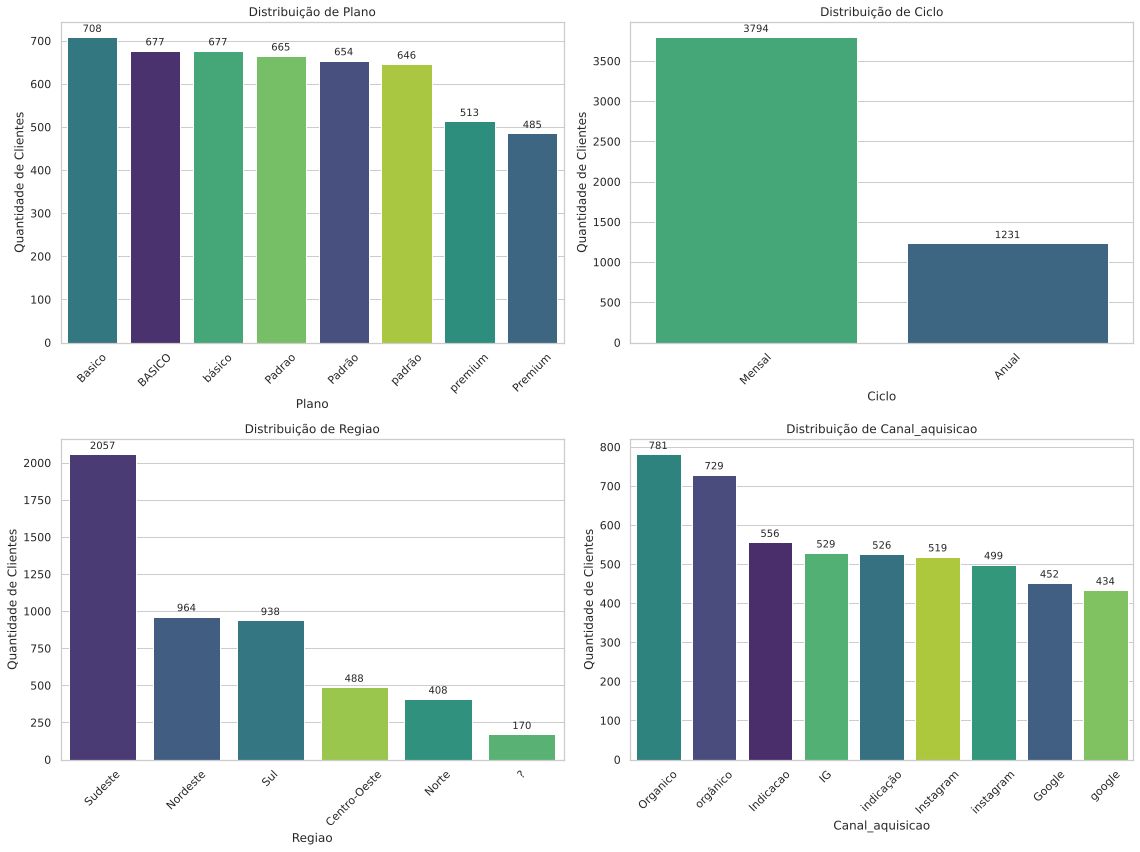

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista das colunas para análise
colunas_analise = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

# Configuração da área dos gráficos (2 linhas, 2 colunas)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(colunas_analise):
    if col in df.columns:
        # Exibir a contagem textual no console
        contagem = df[col].value_counts(dropna=False)
        print(f"\n--- Contagem para a coluna: {col} ---")
        print(contagem)

        # Gerar o gráfico de barras correspondente
        sns.countplot(
            data=df,
            x=col,
            ax=axes[i],
            hue=col,
            palette='viridis',
            legend=False,
            order=contagem.index
        )
        axes[i].set_title(f'Distribuição de {col.capitalize()}')
        axes[i].set_xlabel(col.capitalize())
        axes[i].set_ylabel('Quantidade de Clientes')
        axes[i].tick_params(axis='x', rotation=45)

        # Adicionar os valores numéricos no topo de cada barra
        for p in axes[i].patches:
            height = p.get_height()
            if not pd.isna(height):
                axes[i].annotate(
                    f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10,
                    xytext=(0, 3),
                    textcoords='offset points'
                )
    else:
        print(f"A coluna '{col}' não foi encontrada no DataFrame.")
        axes[i].set_title(f'Coluna {col} não encontrada')

plt.tight_layout()
plt.show()

### 1. Quantidade de valores nulos por coluna

In [5]:
# Contando os valores nulos em cada coluna do DataFrame
nulos_por_coluna = df.isnull().sum()
print(nulos_por_coluna)

cliente_id                   0
idade                        0
plano                        0
ciclo                        0
valor_mensal                 0
regiao                       0
canal_aquisicao              0
nps                          0
data_assinatura              0
data_cancelamento         3509
data_ultimo_acesso          50
data_extracao                0
dias_ativos_ult_mes          0
horas_assistidas_total       0
motivo_cancelamento       3509
churn                        0
dtype: int64


### 2. Linhas do DataFrame onde a coluna `regiao` é "?"

In [6]:
# Exemplo das primeiras 5 linhas onde a região está como '?'
df_regiao_duvida = df[df['regiao'] == '?']
print(f"Quantidade total de registros com '?': {len(df_regiao_duvida)}")
display(df_regiao_duvida.head(5))

Quantidade total de registros com '?': 170


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,Basico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,básico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,Padrão,Anual,3490.0,?,orgânico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,padrão,Mensal,34.9,?,google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,Padrão,Mensal,3490.0,?,orgânico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0


### 3 e 4. Padronização e Substituição de Categorias

In [7]:
# 3. Substituições na coluna 'plano'
mapeamento_plano = {
    'Basico': 'básico',
    'BASICO': 'básico',
    'básico': 'básico',
    'Padrao': 'padrão',
    'Padrão': 'padrão',
    'padrão': 'padrão',
    'Premium': 'premium',
    'premium': 'premium'
}
df['plano'] = df['plano'].map(mapeamento_plano).fillna(df['plano'])

# 4. Substituições na coluna 'canal_aquisicao'
mapeamento_canal = {
    'Organico': 'orgânico',
    'orgânico': 'orgânico',
    'Indicacao': 'indicação',
    'indicação': 'indicação',
    'IG': 'instagram',
    'Instagram': 'instagram',
    'instagram': 'instagram',
    'Google': 'google',
    'google': 'google'
}
df['canal_aquisicao'] = df['canal_aquisicao'].map(mapeamento_canal).fillna(df['canal_aquisicao'])

# Verificação final das contagens
print("Valores únicos atualizados para 'plano':")
print(df['plano'].value_counts(dropna=False))

print("\nValores únicos atualizados para 'canal_aquisicao':")
print(df['canal_aquisicao'].value_counts(dropna=False))

Valores únicos atualizados para 'plano':
plano
básico     2062
padrão     1965
premium     998
Name: count, dtype: int64

Valores únicos atualizados para 'canal_aquisicao':
canal_aquisicao
instagram    1547
orgânico     1510
indicação    1082
google        886
Name: count, dtype: int64


### Verificação de duplicatas

A ordem importa aqui. Antes de padronizar as grafias, `duplicated()` encontra apenas 1
linha repetida, porque `"Padrao"` e `"Padrão"` não batem como texto. **Padronizar primeiro
foi o que tornou as duplicatas visíveis.**

In [8]:
print("cliente_id duplicado :", df['cliente_id'].duplicated().sum())
print("linha inteira duplicada:", df.duplicated().sum())

# Critério adotado: manter a primeira ocorrência de cada cliente.
antes = len(df)
df = df.drop_duplicates(subset='cliente_id', keep='first').copy()
print(f"\nRegistros removidos por duplicidade: {antes - len(df)}")
print(f"Base após deduplicação: {len(df)} linhas")

cliente_id duplicado : 25
linha inteira duplicada: 15

Registros removidos por duplicidade: 25
Base após deduplicação: 5000 linhas


### Substituição de '?' por valores nulos (NaN)

In [9]:
import numpy as np

# Substituir todos os caracteres '?' por NaN (nulo do pandas)
df = df.replace('?', np.nan)

# Verificar se a coluna 'regiao' ainda possui '?' e ver a nova contagem de nulos
print("Valores únicos na coluna 'regiao' após o tratamento:")
print(df['regiao'].value_counts(dropna=False))

print("\nQuantidade de nulos atualizada em cada coluna:")
print(df.isnull().sum())

Valores únicos na coluna 'regiao' após o tratamento:
regiao
Sudeste         2046
Nordeste         959
Sul              933
Centro-Oeste     487
Norte            407
NaN              168
Name: count, dtype: int64

Quantidade de nulos atualizada em cada coluna:
cliente_id                   0
idade                        0
plano                        0
ciclo                        0
valor_mensal                 0
regiao                     168
canal_aquisicao              0
nps                          0
data_assinatura              0
data_cancelamento         3489
data_ultimo_acesso          50
data_extracao                0
dias_ativos_ult_mes          0
horas_assistidas_total       0
motivo_cancelamento       3489
churn                        0
dtype: int64


### Convertendo colunas de data para Datetime

In [10]:
# Lista das colunas de data identificadas no DataFrame
colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']

# Convertendo as colunas selecionadas para o formato datetime
for col in colunas_data:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

# Verificando as alterações de tipos das colunas
print("Novos tipos das colunas no DataFrame:")
display(df[colunas_data].dtypes)

Novos tipos das colunas no DataFrame:


data_assinatura       datetime64[us]
data_cancelamento     datetime64[us]
data_ultimo_acesso    datetime64[us]
data_extracao         datetime64[us]
dtype: object

### Criando as Diferenças de Datas Solicitadas
Cálculo em dias para cada um dos intervalos de datas especificados.

In [11]:
# 1. Diferença entre assinatura e cancelamento
df['diff_assinatura_cancelamento'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days

# 2. Diferença entre assinatura e último acesso
df['diff_assinatura_ultimo_acesso'] = (df['data_ultimo_acesso'] - df['data_assinatura']).dt.days

# 3. Diferença entre assinatura e extração
df['diff_assinatura_extracao'] = (df['data_extracao'] - df['data_assinatura']).dt.days

# 4. Diferença entre cancelamento e último acesso
df['diff_cancelamento_ultimo_acesso'] = (df['data_ultimo_acesso'] - df['data_cancelamento']).dt.days

# 5. Diferença entre cancelamento e extração
df['diff_cancelamento_extracao'] = (df['data_extracao'] - df['data_cancelamento']).dt.days

# 6. Diferença entre último acesso e extração
df['diff_ultimo_acesso_extracao'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# Lista das novas colunas para conferência
novas_colunas = [
    'diff_assinatura_cancelamento',
    'diff_assinatura_ultimo_acesso',
    'diff_assinatura_extracao',
    'diff_cancelamento_ultimo_acesso',
    'diff_cancelamento_extracao',
    'diff_ultimo_acesso_extracao'
]

display(df[novas_colunas].head(10))

,diff_assinatura_cancelamento,diff_assinatura_ultimo_acesso,diff_assinatura_extracao,diff_cancelamento_ultimo_acesso,diff_cancelamento_extracao,diff_ultimo_acesso_extracao
0,NaN,293.0,295,NaN,NaN,2.0
1,NaN,607.0,608,NaN,NaN,1.0
2,607.0,590.0,1047,-17.0,440.0,457.0
3,NaN,286.0,304,NaN,NaN,18.0
4,NaN,270.0,285,NaN,NaN,15.0
5,NaN,424.0,435,NaN,NaN,11.0
6,77.0,58.0,111,-19.0,34.0,53.0
7,NaN,721.0,740,NaN,NaN,19.0
8,235.0,225.0,280,-10.0,45.0,55.0
9,NaN,110.0,116,NaN,NaN,6.0


### Sanity Check nas Colunas de Datas e suas Diferenças

Nesta etapa, validamos a consistência lógica dos dados temporais para garantir que não existam inconsistências como:
1. Clientes com data de cancelamento anterior à data de assinatura.
2. Clientes ativos (`churn == 0`) que possuem `data_cancelamento` preenchida.
3. Clientes com `data_ultimo_acesso` anterior à `data_assinatura`.
4. Datas futuras ou inconsistentes em relação à `data_extracao` (ex: último acesso após a extração).

In [12]:
# 1. Verificando se há cancelamentos antes da assinatura
conflito_cancelamento = df[df['diff_assinatura_cancelamento'] < 0]
print(f"1. Clientes com cancelamento anterior à assinatura: {len(conflito_cancelamento)}")
if len(conflito_cancelamento) > 0:
    display(conflito_cancelamento[['cliente_id', 'data_assinatura', 'data_cancelamento', 'diff_assinatura_cancelamento']].head())

# 2. Verificando se há último acesso antes da assinatura
conflito_acesso = df[df['diff_assinatura_ultimo_acesso'] < 0]
print(f"\n2. Clientes com último acesso anterior à assinatura: {len(conflito_acesso)}")
if len(conflito_acesso) > 0:
    display(conflito_acesso[['cliente_id', 'data_assinatura', 'data_ultimo_acesso', 'diff_assinatura_ultimo_acesso']].head())

# 3. Verificando inconsistência entre Churn e Data de Cancelamento
# Se churn é 0 (não cancelado), não deveria ter data de cancelamento
ativos_com_cancelamento = df[(df['churn'] == 0) & (df['data_cancelamento'].notnull())]
print(f"\n3. Clientes ativos (churn=0) com data de cancelamento preenchida: {len(ativos_com_cancelamento)}")

# Se churn é 1 (cancelado), deveria ter data de cancelamento
cancelados_sem_data = df[(df['churn'] == 1) & (df['data_cancelamento'].isnull())]
print(f"4. Clientes cancelados (churn=1) sem data de cancelamento: {len(cancelados_sem_data)}")

# 4. Verificando se há acessos registrados após a data de extração dos dados
acessos_futuros = df[df['diff_ultimo_acesso_extracao'] < 0]
print(f"\n5. Clientes com último acesso após a data de extração: {len(acessos_futuros)}")
if len(acessos_futuros) > 0:
    display(acessos_futuros[['cliente_id', 'data_ultimo_acesso', 'data_extracao', 'diff_ultimo_acesso_extracao']].head())

1. Clientes com cancelamento anterior à assinatura: 0

2. Clientes com último acesso anterior à assinatura: 1


,cliente_id,data_assinatura,data_ultimo_acesso,diff_assinatura_ultimo_acesso
11,3426,2023-08-18,2023-07-02,-47.0



3. Clientes ativos (churn=0) com data de cancelamento preenchida: 0
4. Clientes cancelados (churn=1) sem data de cancelamento: 0

5. Clientes com último acesso após a data de extração: 0


### Análise de Colunas Numéricas: Estatísticas Descritivas e Nulos

In [13]:
# Identificar colunas numéricas no DataFrame
colunas_numericas = df.select_dtypes(include=['number']).columns.tolist()

print("Colunas numéricas identificadas:")
print(colunas_numericas)

# Calcular a quantidade de nulos especificamente para as colunas numéricas
nulos_numericas = df[colunas_numericas].isnull().sum()

print("\nQuantidade de valores nulos por coluna numérica:")
display(nulos_numericas)

# Exibir estatísticas descritivas das colunas numéricas
print("\nEstatísticas descritivas das colunas numéricas:")
display(df[colunas_numericas].describe())

Colunas numéricas identificadas:
['cliente_id', 'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'diff_assinatura_cancelamento', 'diff_assinatura_ultimo_acesso', 'diff_assinatura_extracao', 'diff_cancelamento_ultimo_acesso', 'diff_cancelamento_extracao', 'diff_ultimo_acesso_extracao']

Quantidade de valores nulos por coluna numérica:


cliente_id                            0
idade                                 0
valor_mensal                          0
nps                                   0
dias_ativos_ult_mes                   0
horas_assistidas_total                0
churn                                 0
diff_assinatura_cancelamento       3489
diff_assinatura_ultimo_acesso        50
diff_assinatura_extracao              0
diff_cancelamento_ultimo_acesso    3504
diff_cancelamento_extracao         3489
diff_ultimo_acesso_extracao          50
dtype: int64


Estatísticas descritivas das colunas numéricas:


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,diff_assinatura_cancelamento,diff_assinatura_ultimo_acesso,diff_assinatura_extracao,diff_cancelamento_ultimo_acesso,diff_cancelamento_extracao,diff_ultimo_acesso_extracao
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,1511.000000,4950.000000,5000.000000,1496.000000,1511.000000,4950.000000
mean,3499.500000,36.339600,414.443740,6.412200,10.646600,281.542120,0.302200,220.488418,371.945859,412.232000,-21.024733,79.678359,40.491515
std,1443.520003,11.696172,1126.731479,2.432833,6.001309,254.802617,0.459257,145.183167,277.210989,270.512016,10.785227,67.890873,55.164339
min,1000.000000,-2.000000,19.900000,0.000000,0.000000,0.000000,0.000000,11.000000,-47.000000,1.000000,-137.000000,3.000000,0.000000
25%,2249.750000,28.750000,19.900000,5.000000,5.000000,65.400000,0.000000,118.000000,163.000000,212.000000,-30.000000,30.000000,10.000000
50%,3499.500000,36.000000,34.900000,7.000000,12.000000,208.250000,0.000000,182.000000,306.000000,349.000000,-21.000000,60.000000,20.000000
75%,4749.250000,44.000000,55.900000,8.000000,15.000000,427.125000,1.000000,289.000000,512.000000,549.000000,-12.000000,107.000000,44.000000
max,5999.000000,300.000000,5590.000000,10.000000,28.000000,900.000000,1.000000,1067.000000,1809.000000,1815.000000,-3.000000,440.000000,469.000000


### Colunas com Valores Nulos e Suas Quantidades

In [14]:
# Calcular a quantidade de nulos por coluna
total_nulos = df.isnull().sum()

# Filtrar apenas as colunas que possuem valores nulos (contagem maior que 0)
colunas_com_nulos = total_nulos[total_nulos > 0].sort_values(ascending=False)

# Mostrar o resultado de forma organizada
print("Colunas que contêm valores nulos e suas respectivas quantidades:")
display(colunas_com_nulos)

Colunas que contêm valores nulos e suas respectivas quantidades:


diff_cancelamento_ultimo_acesso    3504
diff_cancelamento_extracao         3489
data_cancelamento                  3489
diff_assinatura_cancelamento       3489
motivo_cancelamento                3489
regiao                              168
data_ultimo_acesso                   50
diff_assinatura_ultimo_acesso        50
diff_ultimo_acesso_extracao          50
dtype: int64

### Filtrando Inconsistências de Datas (Último Acesso anterior à Assinatura)

In [15]:
# Filtrar o dataset mantendo apenas valores >= 0 ou nulos (NaN)
df_filtrado = df[(df['diff_assinatura_ultimo_acesso'] >= 0) | (df['diff_assinatura_ultimo_acesso'].isnull())].copy()

# Exibir a comparação de tamanho antes e depois do filtro
print(f"Quantidade de registros antes do filtro: {len(df)}")
print(f"Quantidade de registros após o filtro: {len(df_filtrado)}")
print(f"Registros removidos (inconsistentes): {len(df) - len(df_filtrado)}")

# Atualizar o DataFrame original
df = df_filtrado

Quantidade de registros antes do filtro: 5000
Quantidade de registros após o filtro: 4999
Registros removidos (inconsistentes): 1


### Visualização de Distribuições: Boxplots e Histogramas das Colunas Numéricas

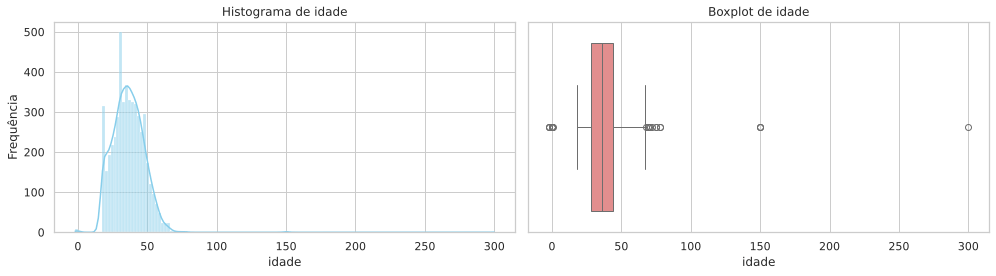

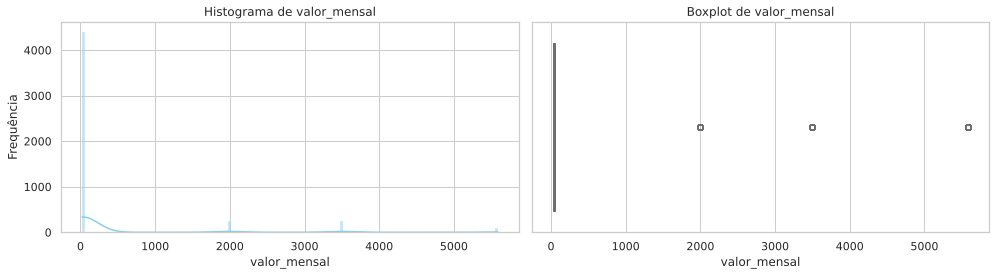

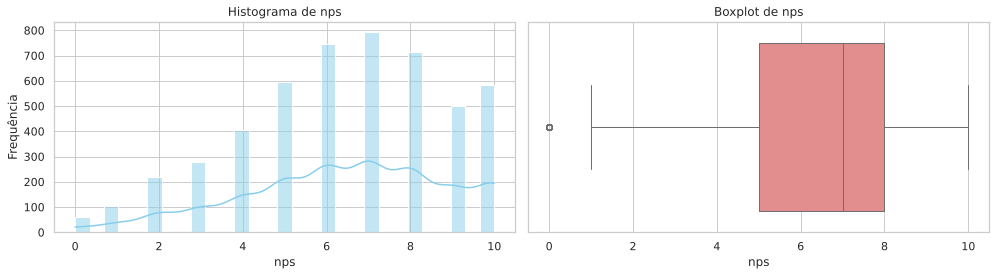

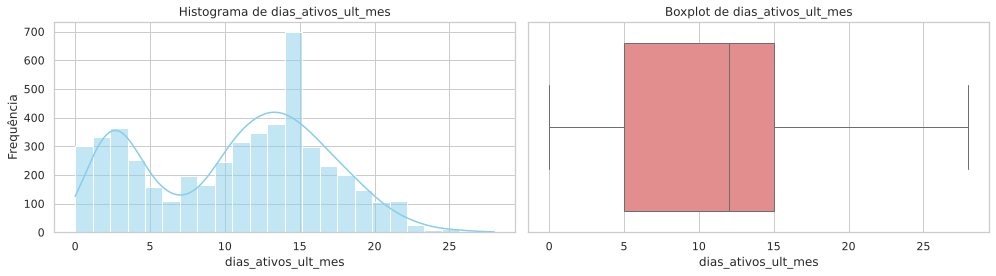

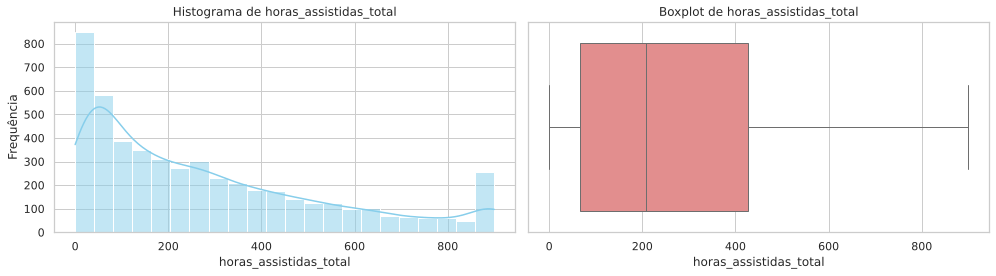

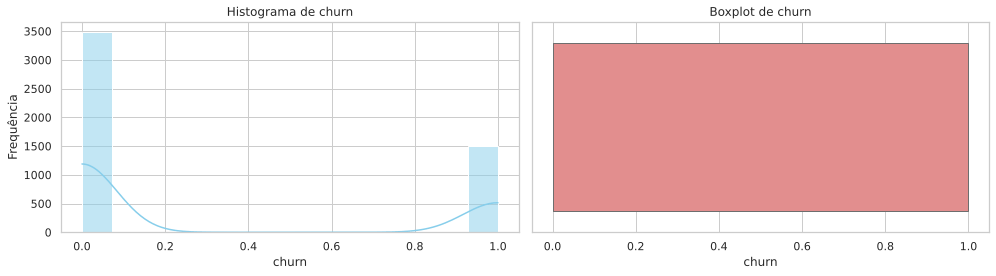

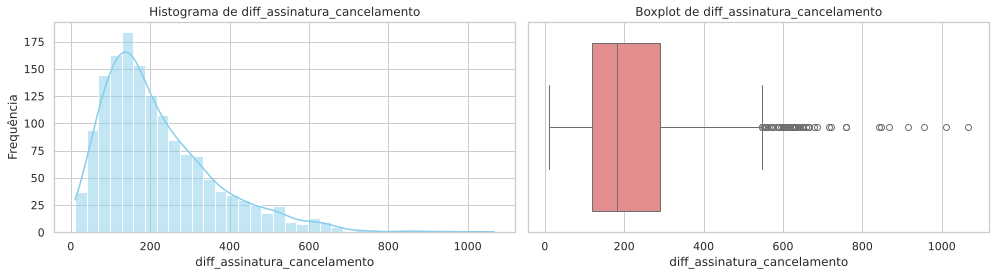

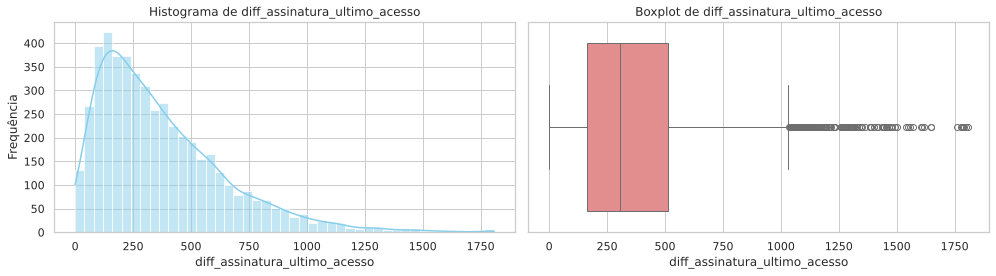

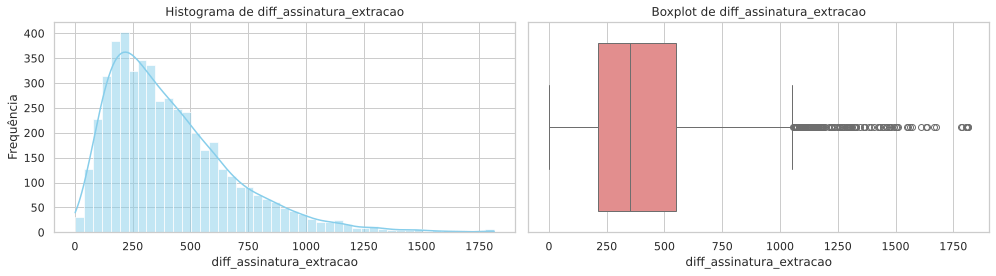

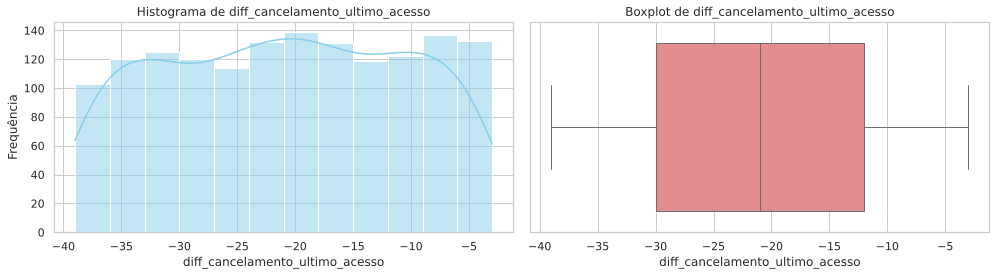

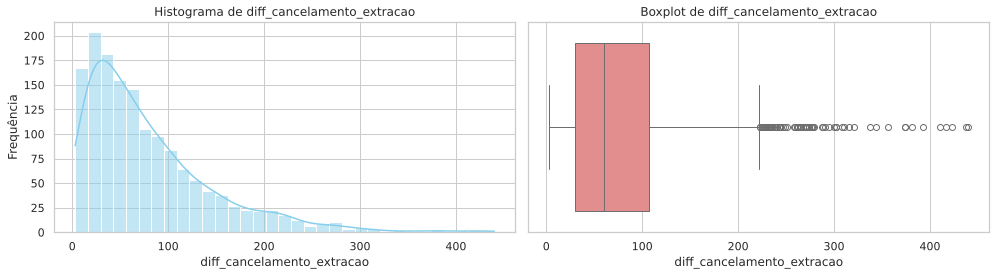

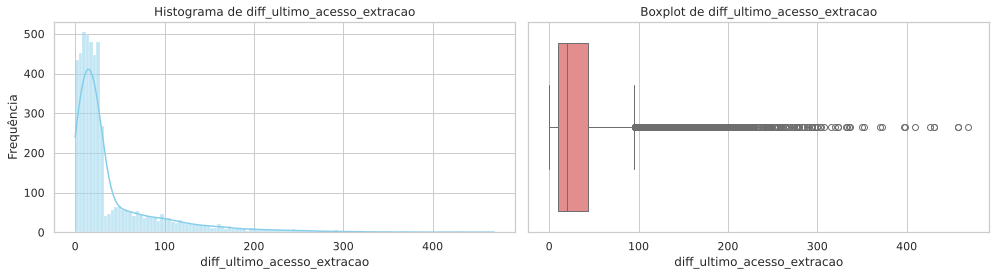

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Selecionar as colunas numéricas excluindo 'cliente_id'
colunas_plot = [col for col in df.select_dtypes(include=['number']).columns if col != 'cliente_id']

# Configurar o estilo de plotagem
sns.set_theme(style="whitegrid")
# Resolucao moderada: mantem os graficos legiveis e o .ipynb leve o bastante
# para o GitHub renderizar a pagina sem truncar.
plt.rcParams["figure.dpi"] = 72

# Gerar os gráficos de forma iterativa para cada coluna
for col in colunas_plot:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # 1. Histograma
    sns.histplot(data=df, x=col, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Histograma de {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequência')

    # 2. Boxplot
    sns.boxplot(data=df, x=col, ax=axes[1], color='lightcoral')
    axes[1].set_title(f'Boxplot de {col}')
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()

### Filtragem por Faixa Etária (Idade entre 18 e 90 anos)

In [17]:
# Filtrar registros mantendo apenas idades entre 18 e 90 anos (inclusive)
df_idade_correta = df_filtrado[(df_filtrado['idade'] >= 18) & (df_filtrado['idade'] <= 90)].copy()

# Exibir estatísticas de remoção
print(f"Quantidade de registros antes do filtro de idade: {len(df_filtrado)}")
print(f"Quantidade de registros após o filtro de idade: {len(df_idade_correta)}")
print(f"Registros de idades removidos: {len(df_filtrado) - len(df_idade_correta)}")

# Atualizar os DataFrames
df_filtrado = df_idade_correta
df = df_idade_correta

Quantidade de registros antes do filtro de idade: 4999
Quantidade de registros após o filtro de idade: 4986
Registros de idades removidos: 13


### Clientes com Valor Mensal Superior a 1000

In [18]:
# Filtrar registros com valor mensal maior que 1000
clientes_valor_alto = df[df['valor_mensal'] > 1000]

print(f"Quantidade de registros com valor mensal maior que 1000: {len(clientes_valor_alto)}")

# Exibir os registros encontrados
if len(clientes_valor_alto) > 0:
    display(clientes_valor_alto)

Quantidade de registros com valor mensal maior que 1000: 596


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,diff_assinatura_cancelamento,diff_assinatura_ultimo_acesso,diff_assinatura_extracao,diff_cancelamento_ultimo_acesso,diff_cancelamento_extracao,diff_ultimo_acesso_extracao
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,286.0,304,NaN,NaN,18.0
14,5581,18,padrão,Mensal,3490.0,Sudeste,orgânico,7,2023-07-22,NaT,...,15,160.7,NaN,0,NaN,189.0,193,NaN,NaN,4.0
29,5979,31,padrão,Mensal,3490.0,Sudeste,instagram,10,2023-08-22,NaT,...,14,117.2,NaN,0,NaN,134.0,162,NaN,NaN,28.0
34,1433,56,padrão,Anual,3490.0,NaN,orgânico,9,2023-04-14,NaT,...,11,180.4,NaN,0,NaN,283.0,292,NaN,NaN,9.0
42,4776,61,básico,Anual,1990.0,Sudeste,orgânico,4,2023-10-01,2023-12-15,...,6,47.8,problema tecnico,1,75.0,55.0,122,-20.0,47.0,67.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4979,4984,30,padrão,Anual,3490.0,Sudeste,indicação,7,2020-12-01,NaT,...,20,900.0,NaN,0,NaN,1138.0,1156,NaN,NaN,18.0
4991,2396,23,padrão,Anual,3490.0,Nordeste,orgânico,8,2021-04-14,NaT,...,18,900.0,NaN,0,NaN,1017.0,1022,NaN,NaN,5.0
5000,5926,37,padrão,Anual,3490.0,Centro-Oeste,orgânico,10,2022-12-01,NaT,...,9,243.6,NaN,0,NaN,402.0,426,NaN,NaN,24.0
5006,4388,18,básico,Anual,1990.0,Nordeste,instagram,9,2023-05-03,NaT,...,11,160.6,NaN,0,NaN,251.0,273,NaN,NaN,22.0


### Contagem de Valores Distintos de `valor_mensal`

In [19]:
# Quantidade de valores distintos
valores_unicos = df['valor_mensal'].nunique()
print(f"Quantidade de valores mensais distintos: {valores_unicos}\n")

# Distribuição dos valores distintos
print("Frequência de cada valor mensal distinto:")
display(df['valor_mensal'].value_counts(dropna=False))

Quantidade de valores mensais distintos: 6

Frequência de cada valor mensal distinto:


valor_mensal
19.9      1799
34.9      1705
55.9       886
1990.0     250
3490.0     242
5590.0     104
Name: count, dtype: int64

### Ajuste de Escala na Coluna `valor_mensal`
Divisão por 100 dos valores que estão acima de 1900 para normalizar as mensalidades.

In [20]:
# Aplicar a divisão por 100 apenas nos valores maiores que 1900
df.loc[df['valor_mensal'] > 1900, 'valor_mensal'] = df.loc[df['valor_mensal'] > 1900, 'valor_mensal'] / 100

# Verificar como ficou a distribuição dos valores após o ajuste
print("Nova distribuição de valores mensais distintos:")
display(df['valor_mensal'].value_counts(dropna=False))

# Verificar se ainda resta algum valor acima de 1000
restante_alto = df[df['valor_mensal'] > 1000]
print(f"\nQuantidade de registros com valor mensal maior que 1000 após o ajuste: {len(restante_alto)}")

Nova distribuição de valores mensais distintos:


valor_mensal
19.9    2049
34.9    1947
55.9     990
Name: count, dtype: int64


Quantidade de registros com valor mensal maior que 1000 após o ajuste: 0


### Verificação Final do DataFrame `df_filtrado`

In [21]:
# 1. Exibir dimensões do DataFrame
print(f"Dimensões atuais de df_filtrado: {df_filtrado.shape[0]} linhas e {df_filtrado.shape[1]} colunas\n")

# 2. Verificar os valores únicos das colunas tratadas para garantir as alterações
print("Valores únicos na coluna 'plano':", df_filtrado['plano'].unique())
print("Valores únicos na coluna 'canal_aquisicao':", df_filtrado['canal_aquisicao'].unique())
print("Valores únicos na coluna 'regiao' (deve conter NaN no lugar de '?'):", df_filtrado['regiao'].unique())

# 3. Verificar intervalo de idade
print(f"\nIdade mínima: {df_filtrado['idade'].min()} | Idade máxima: {df_filtrado['idade'].max()}")

# 4. Verificar intervalo de valor_mensal (deve ser menor que 1000)
print(f"Valor mensal máximo atual: {df_filtrado['valor_mensal'].max()}")

# 5. Exibir uma amostra das primeiras linhas do DataFrame consolidado
display(df_filtrado.head(5))

Dimensões atuais de df_filtrado: 4986 linhas e 22 colunas

Valores únicos na coluna 'plano': <StringArray>
['básico', 'padrão', 'premium']
Length: 3, dtype: str
Valores únicos na coluna 'canal_aquisicao': <StringArray>
['indicação', 'orgânico', 'google', 'instagram']
Length: 4, dtype: str
Valores únicos na coluna 'regiao' (deve conter NaN no lugar de '?'): <StringArray>
['Sudeste', 'Nordeste', 'Sul', 'Norte', nan, 'Centro-Oeste']
Length: 6, dtype: str

Idade mínima: 18 | Idade máxima: 78
Valor mensal máximo atual: 55.9


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,diff_assinatura_cancelamento,diff_assinatura_ultimo_acesso,diff_assinatura_extracao,diff_cancelamento_ultimo_acesso,diff_cancelamento_extracao,diff_ultimo_acesso_extracao
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,15,276.0,NaN,0,NaN,293.0,295,NaN,NaN,2.0
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,14,394.9,NaN,0,NaN,607.0,608,NaN,NaN,1.0
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,5,257.0,PREÇO,1,607.0,590.0,1047,-17.0,440.0,457.0
3,3454,46,básico,Anual,19.9,Sul,google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,286.0,304,NaN,NaN,18.0
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,11,205.3,NaN,0,NaN,270.0,285,NaN,NaN,15.0


### Criação de Novas Métricas de Negócio
Criando as colunas `recencia`, `meses_assinatura` e `receita_acumulada` de acordo com as regras solicitadas.

In [22]:
import numpy as np

# 1. recencia = diff data ultimo acesso data extracao (que já temos calculado na coluna diff_ultimo_acesso_extracao)
df_filtrado['recencia'] = df_filtrado['diff_ultimo_acesso_extracao']

# 2. meses_assinatura
# Condicional: se data_cancelamento for nula, usar (data_extracao - data_assinatura) / 30.
# Caso contrário, usar (data_cancelamento - data_assinatura) / 30.
diff_ativos = (df_filtrado['data_extracao'] - df_filtrado['data_assinatura']).dt.days / 30
diff_cancelados = (df_filtrado['data_cancelamento'] - df_filtrado['data_assinatura']).dt.days / 30

df_filtrado['meses_assinatura'] = np.where(
    df_filtrado['data_cancelamento'].isnull(),
    diff_ativos,
    diff_cancelados
)

# 3. receita_acumulada = valor_mensal * meses_assinatura
df_filtrado['receita_acumulada'] = df_filtrado['valor_mensal'] * df_filtrado['meses_assinatura']

# Atualizar df de referência
df = df_filtrado

# Exibir o resultado das novas colunas para conferência
colunas_novas = ['data_assinatura', 'data_cancelamento', 'data_extracao', 'valor_mensal', 'recencia', 'meses_assinatura', 'receita_acumulada']
display(df_filtrado[colunas_novas].head(10))

,data_assinatura,data_cancelamento,data_extracao,valor_mensal,recencia,meses_assinatura,receita_acumulada
0,2023-04-11,NaT,2024-01-31,19.9,2.0,9.833333,195.683333
1,2022-06-02,NaT,2024-01-31,34.9,1.0,20.266667,707.306667
2,2021-03-20,2022-11-17,2024-01-31,55.9,457.0,20.233333,1131.043333
3,2023-04-02,NaT,2024-01-31,19.9,18.0,10.133333,201.653333
4,2023-04-21,NaT,2024-01-31,19.9,15.0,9.500000,189.050000
5,2022-11-22,NaT,2024-01-31,55.9,11.0,14.500000,810.550000
6,2023-10-12,2023-12-28,2024-01-31,19.9,53.0,2.566667,51.076667
7,2022-01-21,NaT,2024-01-31,34.9,19.0,24.666667,860.866667
8,2023-04-26,2023-12-17,2024-01-31,19.9,55.0,7.833333,155.883333
9,2023-10-07,NaT,2024-01-31,19.9,6.0,3.866667,76.946667


### Exportando o Pipeline de Tratamento para o Script `exec_univariado.py`
O bloco abaixo cria o arquivo Python consolidado com todos os tratamentos aplicados na nossa análise univariada.

> A célula abaixo gera o pipeline como script reutilizável. A versão versionada deste
> arquivo está em [`src/exec_univariado.py`](../src/exec_univariado.py), e pode ser usada
> sem o notebook:
>
> ```python
> from src.exec_univariado import executar_pipeline
> df = executar_pipeline()
> ```


In [23]:
%%writefile exec_univariado.py
# -*- coding: utf-8 -*-
"""
exec_univariado.py

Pipeline consolidado de limpeza, saneamento e engenharia de atributos da base de
assinantes, reproduzindo as etapas da análise univariada do notebook.

Uso:
    from exec_univariado import executar_pipeline
    df = executar_pipeline()                  # lê do repositório público do curso
    df = executar_pipeline("dados/base.csv")  # ou de um caminho local
"""

import numpy as np
import pandas as pd

BASE_DADOS = (
    "https://raw.githubusercontent.com/unipds-ciencia-de-dados/ciencia-de-dados/"
    "main/disciplina-01-dados-ia-negocios/disc01-mod03-aula03"
)

COLUNAS_DATA = [
    "data_assinatura",
    "data_cancelamento",
    "data_ultimo_acesso",
    "data_extracao",
]

MAPA_PLANO = {
    "Basico": "básico", "BASICO": "básico", "básico": "básico",
    "Padrao": "padrão", "Padrão": "padrão", "padrão": "padrão",
    "Premium": "premium", "premium": "premium",
}

MAPA_CANAL = {
    "Organico": "orgânico", "orgânico": "orgânico",
    "Indicacao": "indicação", "indicação": "indicação",
    "IG": "instagram", "Instagram": "instagram", "instagram": "instagram",
    "Google": "google", "google": "google",
}


def executar_pipeline(caminho_csv=None, verboso=True):
    """Devolve o DataFrame limpo, deduplicado e enriquecido."""
    caminho_csv = caminho_csv or f"{BASE_DADOS}/clientes_base.csv"

    def log(msg):
        if verboso:
            print(msg)

    log("[1/7] Carregando a base...")
    df = pd.read_csv(caminho_csv)
    log(f"       {len(df)} registros carregados")

    log("[2/7] Padronizando categorias...")
    # A padronização vem ANTES da deduplicação de propósito: sem ela, linhas
    # idênticas escritas com grafias diferentes não são reconhecidas como duplicadas.
    df["plano"] = df["plano"].map(MAPA_PLANO).fillna(df["plano"])
    df["canal_aquisicao"] = df["canal_aquisicao"].map(MAPA_CANAL).fillna(df["canal_aquisicao"])
    df = df.replace("?", np.nan)

    log("[3/7] Removendo duplicatas...")
    antes = len(df)
    df = df.drop_duplicates(subset="cliente_id", keep="first").copy()
    log(f"       {antes - len(df)} registros duplicados removidos")

    log("[4/7] Convertendo datas...")
    for col in COLUNAS_DATA:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors="coerce")

    log("[5/7] Aplicando filtros de integridade...")
    antes = len(df)
    dias_ate_ultimo_acesso = (df["data_ultimo_acesso"] - df["data_assinatura"]).dt.days
    df = df[(dias_ate_ultimo_acesso >= 0) | (dias_ate_ultimo_acesso.isnull())].copy()
    df = df[(df["idade"] >= 18) & (df["idade"] <= 90)].copy()
    log(f"       {antes - len(df)} registros inconsistentes removidos")

    log("[6/7] Corrigindo erro de escala em valor_mensal...")
    # Valores como 1990 e 3490 são 19,90 e 34,90 com a vírgula decimal perdida na exportação.
    fora_de_escala = df["valor_mensal"] > 1900
    df.loc[fora_de_escala, "valor_mensal"] = df.loc[fora_de_escala, "valor_mensal"] / 100
    log(f"       {int(fora_de_escala.sum())} valores corrigidos")

    log("[7/7] Criando métricas de negócio...")
    df["recencia"] = (df["data_extracao"] - df["data_ultimo_acesso"]).dt.days
    meses_ativo = (df["data_extracao"] - df["data_assinatura"]).dt.days / 30
    meses_cancelado = (df["data_cancelamento"] - df["data_assinatura"]).dt.days / 30
    df["meses_assinatura"] = np.where(
        df["data_cancelamento"].isnull(), meses_ativo, meses_cancelado
    )
    df["receita_acumulada"] = df["valor_mensal"] * df["meses_assinatura"]

    log(f"\nPipeline concluído: {len(df)} registros finais, {df.shape[1]} colunas")
    return df


if __name__ == "__main__":
    base = executar_pipeline()
    print(base[["plano", "valor_mensal", "recencia", "meses_assinatura", "receita_acumulada"]].head())


Writing exec_univariado.py


### Criação do DataFrame `df_analise` para Clientes com Histórico Mínimo
Filtramos o dataset para garantir que os clientes possuam pelo menos 220 dias entre a assinatura e a extração (`diff_assinatura_extracao >= 220`).

In [24]:
# Criar o novo DataFrame aplicando o filtro solicitado
df_analise = df_filtrado[df_filtrado['diff_assinatura_extracao'] >= 220].copy()

# Exibir a quantidade de registros antes e depois do filtro
print(f"Quantidade de registros no df_filtrado original: {len(df_filtrado)}")
print(f"Quantidade de registros no df_analise: {len(df_analise)}")
print(f"Registros filtrados (removidos): {len(df_filtrado) - len(df_analise)}")

# Visualizar uma amostra das primeiras linhas do novo DataFrame
display(df_analise.head())

Quantidade de registros no df_filtrado original: 4986
Quantidade de registros no df_analise: 3645
Registros filtrados (removidos): 1341


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,churn,diff_assinatura_cancelamento,diff_assinatura_ultimo_acesso,diff_assinatura_extracao,diff_cancelamento_ultimo_acesso,diff_cancelamento_extracao,diff_ultimo_acesso_extracao,recencia,meses_assinatura,receita_acumulada
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,0,NaN,293.0,295,NaN,NaN,2.0,2.0,9.833333,195.683333
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,0,NaN,607.0,608,NaN,NaN,1.0,1.0,20.266667,707.306667
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,1,607.0,590.0,1047,-17.0,440.0,457.0,457.0,20.233333,1131.043333
3,3454,46,básico,Anual,19.9,Sul,google,10,2023-04-02,NaT,...,0,NaN,286.0,304,NaN,NaN,18.0,18.0,10.133333,201.653333
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,0,NaN,270.0,285,NaN,NaN,15.0,15.0,9.500000,189.050000


## Análise de Churn com Variáveis Numéricas

Para cada variável numérica, visualizamos a distribuição de densidade agrupada pelo Churn (0 e 1) e extraímos as estatísticas descritivas de cada grupo.


 ANÁLISE DA VARIÁVEL NUMÉRICA: IDADE 


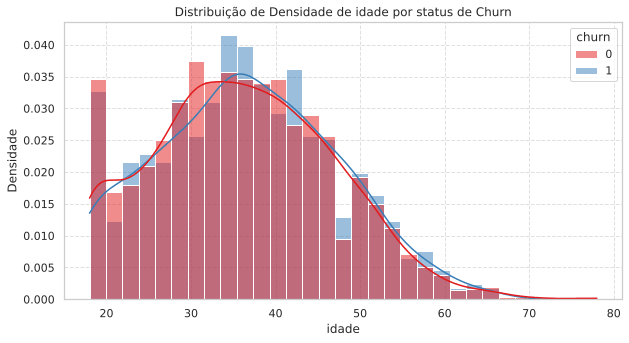


Estatísticas Descritivas de idade por grupo de Churn:


churn,0,1
count,2761.000000,884.000000
mean,36.145599,36.632353
std,10.650432,10.622287
min,18.000000,18.000000
25%,29.000000,29.000000
50%,36.000000,36.000000
75%,44.000000,44.000000
max,78.000000,66.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: VALOR_MENSAL 


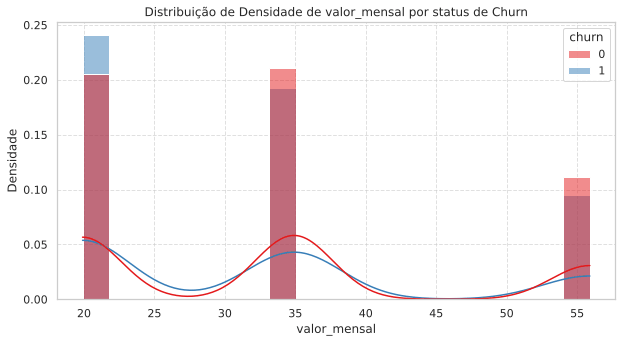


Estatísticas Descritivas de valor_mensal por grupo de Churn:


churn,0,1
count,2761.000000,884.000000
mean,33.499420,31.838914
std,13.369565,13.142253
min,19.900000,19.900000
25%,19.900000,19.900000
50%,34.900000,34.900000
75%,34.900000,34.900000
max,55.900000,55.900000



 ANÁLISE DA VARIÁVEL NUMÉRICA: NPS 


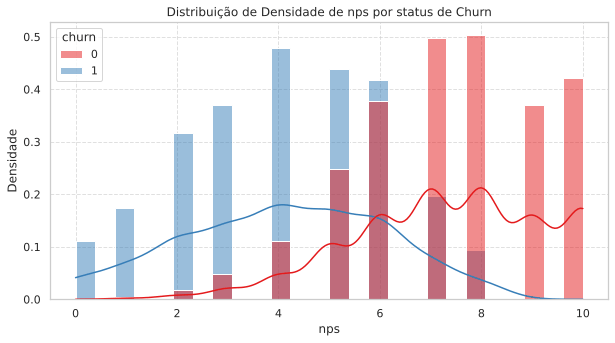


Estatísticas Descritivas de nps por grupo de Churn:


churn,0,1
count,2761.000000,884.000000
mean,7.380659,4.102941
std,1.877298,1.996495
min,1.000000,0.000000
25%,6.000000,3.000000
50%,7.000000,4.000000
75%,9.000000,6.000000
max,10.000000,8.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: DIAS_ATIVOS_ULT_MES 


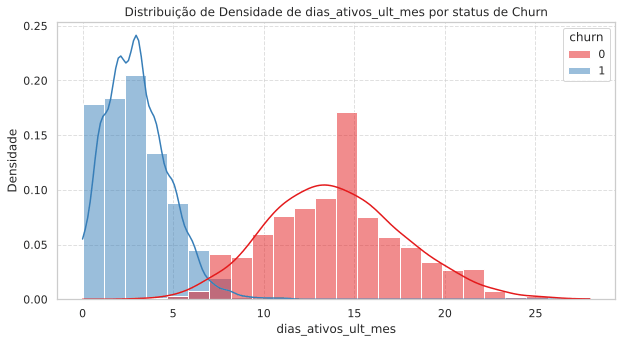


Estatísticas Descritivas de dias_ativos_ult_mes por grupo de Churn:


churn,0,1
count,2761.000000,884.000000
mean,13.992032,2.967195
std,3.756725,1.723874
min,3.000000,0.000000
25%,11.000000,2.000000
50%,14.000000,3.000000
75%,16.000000,4.000000
max,28.000000,11.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: HORAS_ASSISTIDAS_TOTAL 


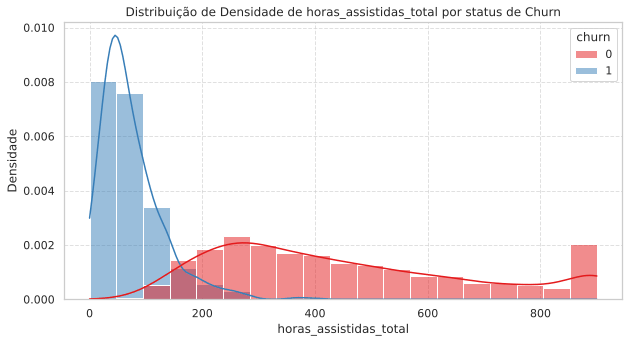


Estatísticas Descritivas de horas_assistidas_total por grupo de Churn:


churn,0,1
count,2761.000000,884.000000
mean,448.960666,73.232805
std,227.056729,55.297560
min,73.900000,0.000000
25%,265.500000,35.625000
50%,395.500000,59.100000
75%,602.500000,96.625000
max,900.000000,400.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: DIFF_ASSINATURA_ULTIMO_ACESSO 


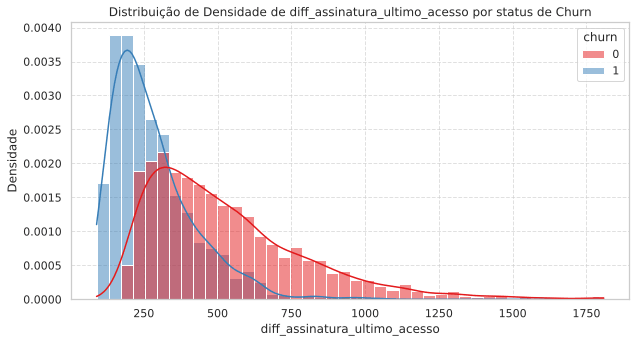


Estatísticas Descritivas de diff_assinatura_ultimo_acesso por grupo de Churn:


churn,0,1
count,2736.000000,874.000000
mean,528.486842,279.056064
std,266.396831,138.760337
min,192.000000,90.000000
25%,326.750000,176.000000
50%,465.000000,245.000000
75%,659.250000,343.000000
max,1809.000000,1040.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: DIFF_ASSINATURA_EXTRACAO 


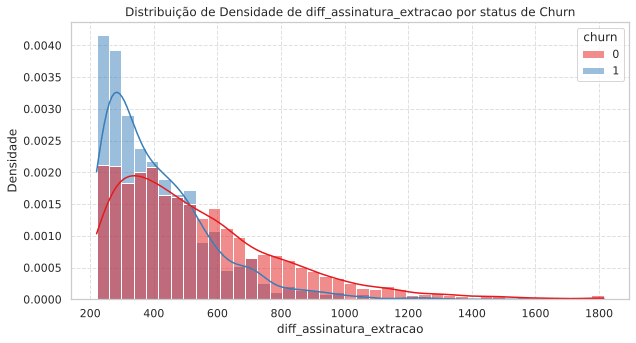


Estatísticas Descritivas de diff_assinatura_extracao por grupo de Churn:


churn,0,1
count,2761.000000,884.000000
mean,542.839551,409.961538
std,265.681546,166.875974
min,220.000000,220.000000
25%,341.000000,282.750000
50%,481.000000,365.500000
75%,675.000000,495.000000
max,1815.000000,1276.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: RECENCIA 


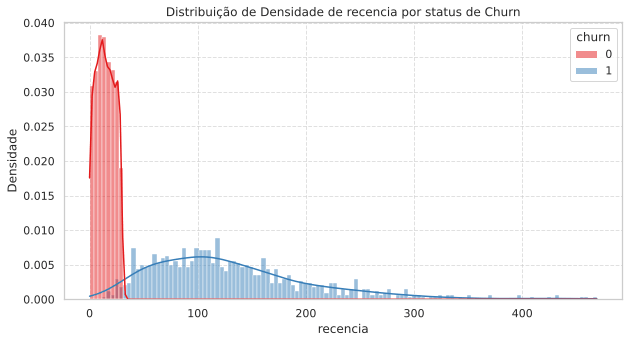


Estatísticas Descritivas de recencia por grupo de Churn:


churn,0,1
count,2736.000000,874.000000
mean,14.595029,130.084668
std,8.498140,74.190474
min,0.000000,13.000000
25%,8.000000,75.250000
50%,14.000000,117.000000
75%,22.000000,165.000000
max,29.000000,469.000000



 ANÁLISE DA VARIÁVEL NUMÉRICA: MESES_ASSINATURA 


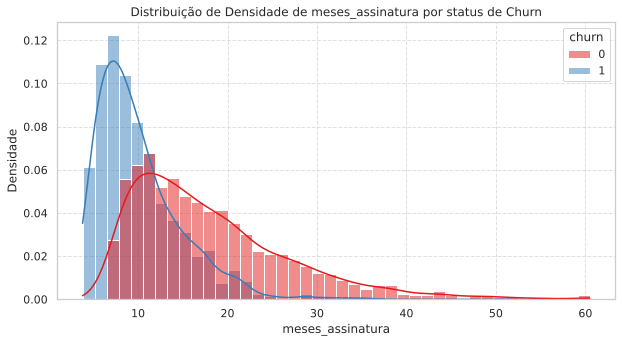


Estatísticas Descritivas de meses_assinatura por grupo de Churn:


churn,0,1
count,2761.000000,884.000000
mean,18.094652,10.018137
std,8.856052,4.621022
min,7.333333,3.800000
25%,11.366667,6.666667
50%,16.033333,8.900000
75%,22.500000,12.133333
max,60.500000,35.566667



 ANÁLISE DA VARIÁVEL NUMÉRICA: RECEITA_ACUMULADA 


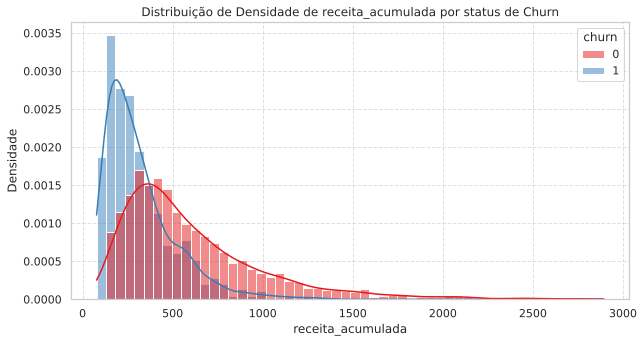


Estatísticas Descritivas de receita_acumulada por grupo de Churn:


churn,0,1
count,2761.000000,884.000000
mean,605.191646,315.961497
std,395.963031,195.464694
min,145.933333,77.610000
25%,329.013333,171.749167
50%,492.856667,263.495000
75%,762.103333,392.334167
max,2893.756667,1341.600000


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Lista das variáveis numéricas adaptadas aos nomes reais das colunas no DataFrame
var_numericas = [
    'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total',
    'diff_assinatura_ultimo_acesso', 'diff_assinatura_extracao', 'recencia',
    'meses_assinatura', 'receita_acumulada'
]

for col in var_numericas:
    if col in df_analise.columns:
        print(f"\n" + "="*80)
        print(f" ANÁLISE DA VARIÁVEL NUMÉRICA: {col.upper()} ")
        print("="*80)

        # 1. Histograma de Densidade Sobreposto
        plt.figure(figsize=(10, 5))
        sns.histplot(
            data=df_analise,
            x=col,
            hue='churn',
            kde=True,
            stat='density',
            common_norm=False,
            palette='Set1',
            alpha=0.5
        )
        plt.title(f'Distribuição de Densidade de {col} por status de Churn')
        plt.xlabel(col)
        plt.ylabel('Densidade')
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.show()

        # 2. Tabela de estatísticas por grupo de churn
        stats_churn = df_analise.groupby('churn')[col].describe().T
        print(f"\nEstatísticas Descritivas de {col} por grupo de Churn:")
        display(stats_churn)
    else:
        print(f"A coluna '{col}' não foi encontrada em df_analise.")

## Análise de Churn com Variáveis Categóricas

Calculamos a taxa de Churn (em porcentagem) para cada uma das categorias das variáveis selecionadas.

In [26]:
# Lista das variáveis categóricas
var_categoricas = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

for col in var_categoricas:
    if col in df_analise.columns:
        print(f"\n" + "="*80)
        print(f" TAXA DE CHURN POR CATEGORIA: {col.upper()} ")
        print("="*80)

        # Calcular a taxa de churn (média de churn * 100) e a contagem de clientes
        tabela_churn = df_analise.groupby(col, dropna=False).agg(
            total_clientes=('churn', 'count'),
            taxa_churn_pct=('churn', lambda x: x.mean() * 100)
        ).reset_index()

        # Renomear colunas para melhor entendimento
        tabela_churn.columns = [col, 'Total de Clientes', 'Taxa de Churn (%)']
        tabela_churn = tabela_churn.sort_values(by='Taxa de Churn (%)', ascending=False)

        display(tabela_churn)
    else:
        print(f"A coluna '{col}' não foi encontrada em df_analise.")


 TAXA DE CHURN POR CATEGORIA: PLANO 


,plano,Total de Clientes,Taxa de Churn (%)
0,básico,1477,27.285037
1,padrão,1426,22.580645
2,premium,742,21.428571



 TAXA DE CHURN POR CATEGORIA: CICLO 


,ciclo,Total de Clientes,Taxa de Churn (%)
1,Mensal,2731,24.313438
0,Anual,914,24.070022



 TAXA DE CHURN POR CATEGORIA: REGIAO 


,regiao,Total de Clientes,Taxa de Churn (%)
5,NaN,126,26.984127
0,Centro-Oeste,352,26.420455
2,Norte,296,25.337838
4,Sul,702,24.786325
1,Nordeste,716,24.022346
3,Sudeste,1453,23.124570



 TAXA DE CHURN POR CATEGORIA: CANAL_AQUISICAO 


,canal_aquisicao,Total de Clientes,Taxa de Churn (%)
0,google,630,27.142857
2,instagram,1122,24.866310
3,orgânico,1104,23.097826
1,indicação,789,22.686946


> **Sua leitura dos cruzamentos:**
>
> _Qual plano, ciclo, região e canal concentram mais cancelamento? A diferença entre
> categorias é grande o suficiente para justificar ação, ou está dentro do ruído?
> Lembre que associação não é explicação — o que aqui vira hipótese, e não conclusão?_

### Execução e Plotagem da Análise de Churn

### Análise de Cohort de Retenção
Nesta etapa, calculamos a permanência mensal de cada cliente, expandimos os dados para representar a atividade ao longo dos meses de vida e geramos o Heatmap de Retenção a partir de dezembro de 2022 até o limite de 24 meses.

> **Janela de observação.** A extração dos dados é de 2024-01-31, então cada safra
> tem um número diferente de meses observáveis: a de 2022-12 pôde ser acompanhada por
> 13 meses, a de 2023-12 por apenas 1. As células além desse limite ficam **em branco**
> no heatmap — não são retenção zero, são ausência de dado. Preenchê-las com zero
> sugeriria que todas as coortes morrem, quando na verdade a observação é que terminou.


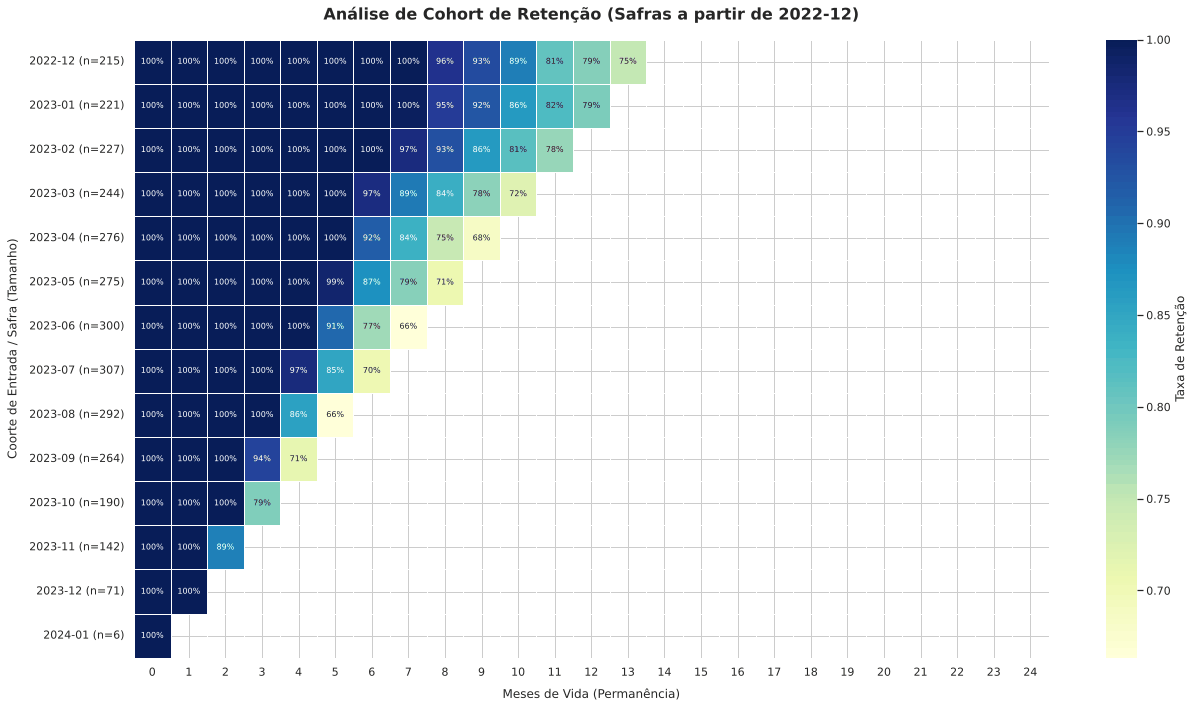

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparação dos dados
df_cohort = df_filtrado.copy()

# Definir coorte como ano-mês de assinatura
df_cohort['coorte'] = df_cohort['data_assinatura'].dt.to_period('M')

# Definir fim de permanência: se cancelamento é nulo, usar data de extração
df_cohort['fim_permanencia'] = df_cohort['data_cancelamento'].fillna(df_cohort['data_extracao'])

# Calcular a diferença em meses entre a assinatura e o fim da permanência
# Diferença em meses = (Ano_Fim - Ano_Inicio) * 12 + (Mes_Fim - Mes_Inicio)
df_cohort['meses_permanencia'] = (
    (df_cohort['fim_permanencia'].dt.year - df_cohort['data_assinatura'].dt.year) * 12 +
    (df_cohort['fim_permanencia'].dt.month - df_cohort['data_assinatura'].dt.month)
)

# 2. Expansão dos dados: contar o cliente como ativo para cada mês de vida intermediário
records = []
for _, row in df_cohort.iterrows():
    coorte_val = str(row['coorte'])
    max_mes = int(row['meses_permanencia'])
    for mes_vida in range(max_mes + 1):
        records.append({
            'coorte': coorte_val,
            'mes_vida': mes_vida,
            'cliente_id': row['cliente_id']
        })

df_expandido = pd.DataFrame(records)

# 3. Montagem da matriz de contagem
matriz_contagem = df_expandido.pivot_table(
    index='coorte',
    columns='mes_vida',
    values='cliente_id',
    aggfunc='nunique'
).fillna(0)

# Guardar o tamanho inicial de cada coorte (mês de vida 0)
tamanhos_coorte = matriz_contagem[0].astype(int)

# Converter em porcentagem de retenção
matriz_retencao = matriz_contagem.divide(tamanhos_coorte, axis=0)

# Mascarar o que está FORA da janela de observação de cada coorte.
# A extração é de 2024-01-31, então a safra de 2022-12 só pôde ser observada por 13 meses.
# Sem esta máscara, o fillna(0) acima transforma "ainda não observável" em "0% de retenção",
# e o heatmap sugere que toda coorte morre — quando na verdade os dados apenas acabaram.
# É o mesmo viés de maturação que justifica o filtro de 220 dias na análise bivariada.
data_extracao = df_cohort['data_extracao'].max()
meses_observaveis = {
    str(p): (data_extracao.year - p.year) * 12 + (data_extracao.month - p.month)
    for p in df_cohort['coorte'].dropna().unique()
}

for coorte in matriz_retencao.index:
    limite = meses_observaveis[coorte]
    fora_da_janela = [c for c in matriz_retencao.columns if c > limite]
    matriz_retencao.loc[coorte, fora_da_janela] = np.nan

# 4. Ajustar os rótulos do eixo Y para incluir o tamanho da coorte: "AAAA-MM (n=X)"
novos_rotulos_y = {
    coorte: f"{coorte} (n={tamanhos_coorte[coorte]})"
    for coorte in matriz_retencao.index
}
matriz_retencao_renomeada = matriz_retencao.rename(index=novos_rotulos_y)

# Filtrar para exibir safras a partir de 2022-12 e colunas (meses de vida) de 0 a 24
coortes_filtradas = [c for c in matriz_retencao.index if c >= '2022-12']
rotulos_filtrados = [novos_rotulos_y[c] for c in coortes_filtradas]

# Limitar colunas até o mês 24 (se existirem na matriz)
colunas_filtradas = [col for col in range(25) if col in matriz_retencao.columns]

matriz_plot = matriz_retencao_renomeada.loc[rotulos_filtrados, colunas_filtradas]

# 5. Visualização em Heatmap
plt.figure(figsize=(18, 10))
sns.heatmap(
    matriz_plot,
    annot=True,
    fmt=".0%",
    cmap="YlGnBu",
    cbar_kws={'label': 'Taxa de Retenção'},
    annot_kws={"size": 8},
    linewidths=0.5
)

plt.title('Análise de Cohort de Retenção (Safras a partir de 2022-12)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Meses de Vida (Permanência)', fontsize=12, labelpad=10)
plt.ylabel('Coorte de Entrada / Safra (Tamanho)', fontsize=12, labelpad=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Framework 2 — RFM Adaptado a Streaming

Nesta seção, realizamos uma segmentação dos clientes ativos (`churn == 0`) com base no comportamento de Recência, Frequência e Monetário adaptados para o modelo de assinaturas de streaming.

> **Nota metodológica.** A segmentação usa `dias_ativos_ult_mes` como dimensão de
> Frequência, e isso só é legítimo porque a base foi filtrada para `churn == 0` logo
> na primeira linha da célula seguinte.
>
> Para **prever** cancelamento, essa variável seria vazamento de dado: quem já cancelou
> registra zero dias ativos por definição — o zero é consequência da saída, não causa
> antecedente. Aqui a pergunta é outra: estamos **descrevendo o estado atual** de
> clientes ativos para decidir quem recebe ação. Não há futuro sendo espiado.

Quantidade de clientes ativos elegíveis para o RFM: 3445

Limites das quebras de Recência (dias desde o último acesso):
recencia
(-0.001, 6.0]    786
(6.0, 11.0]      599
(11.0, 17.0]     700
(17.0, 23.0]     677
(23.0, 29.0]     683
Name: count, dtype: int64

Limites das quebras de Frequência (dias ativos no último mês):
dias_ativos_ult_mes
(2.999, 11.0]    917
(11.0, 13.0]     707
(13.0, 15.0]     692
(15.0, 17.0]     522
(17.0, 28.0]     607
Name: count, dtype: int64

Distribuição de notas da dimensão Monetário (M):
M
1    1339
3    1395
5     711
Name: count, dtype: int64

 DISTRIBUIÇÃO DOS CLIENTES POR SEGMENTO RFM 


,Segmento,Quantidade de Clientes,Porcentagem (%)
0,Regulares,973,28.243832
1,Em risco,708,20.551524
2,Adormecidos,652,18.925980
3,Novos/Ativos recentes,648,18.809869
4,Engajados,464,13.468795


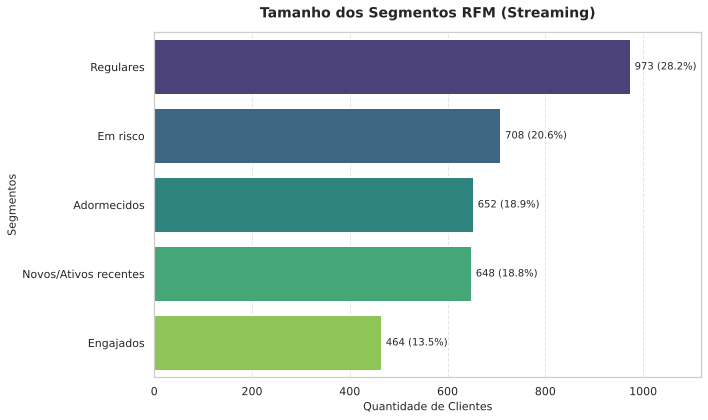

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtrar apenas clientes ativos (churn == 0) e remover nulos em 'recencia'
df_rfm = df_filtrado[df_filtrado['churn'] == 0].copy()
df_rfm = df_rfm.dropna(subset=['recencia'])

print(f"Quantidade de clientes ativos elegíveis para o RFM: {len(df_rfm)}")

# 2. Atribuição de notas de 1 a 5
# R (Recência): menor valor é melhor -> invertendo rótulos (menor valor recebe nota 5)
df_rfm['R'] = pd.qcut(df_rfm['recencia'], q=5, labels=[5, 4, 3, 2, 1], duplicates='drop').astype(int)

# F (Frequência): maior valor de dias_ativos_ult_mes é melhor -> nota 5
df_rfm['F'] = pd.qcut(df_rfm['dias_ativos_ult_mes'], q=5, labels=[1, 2, 3, 4, 5], duplicates='drop').astype(int)

# M (Monetário): valor_mensal tem apenas 3 valores distintos (os 3 planos do catálogo).
# Usar rank percentual aqui produziria apenas as notas 1, 2 e 4 — nunca 3 nem 5.
# Mapeamos os planos diretamente para os extremos e o centro da escala.
mapa_monetario = {19.9: 1, 34.9: 3, 55.9: 5}
df_rfm['M'] = df_rfm['valor_mensal'].map(mapa_monetario)
assert df_rfm['M'].notna().all(), 'Há valor_mensal fora do catálogo de planos'

# Exibir os limites dos limites/quintis das dimensões para transparência
print("\nLimites das quebras de Recência (dias desde o último acesso):")
print(pd.qcut(df_rfm['recencia'], q=5, duplicates='drop').value_counts().sort_index())

print("\nLimites das quebras de Frequência (dias ativos no último mês):")
print(pd.qcut(df_rfm['dias_ativos_ult_mes'], q=5, duplicates='drop').value_counts().sort_index())

print("\nDistribuição de notas da dimensão Monetário (M):")
print(df_rfm['M'].value_counts().sort_index())

# 3. Criar código RFM
df_rfm['codigo_RFM'] = 'R' + df_rfm['R'].astype(str) + 'F' + df_rfm['F'].astype(str) + 'M' + df_rfm['M'].astype(str)

# 4. Classificação dos clientes em segmentos com base nas regras de R e F
def definir_segmento(row):
    r = row['R']
    f = row['F']
    if r >= 4 and f >= 4:
        return "Engajados"
    elif r <= 2 and f >= 3:
        return "Em risco"
    elif r >= 4 and f <= 2:
        return "Novos/Ativos recentes"
    elif r <= 2 and f <= 2:
        return "Adormecidos"
    else:
        return "Regulares"

df_rfm['segmento_RFM'] = df_rfm.apply(definir_segmento, axis=1)

# 5. Contagem e porcentagem de clientes por segmento
tabela_segmentos = df_rfm['segmento_RFM'].value_counts().reset_index()
tabela_segmentos.columns = ['Segmento', 'Quantidade de Clientes']
tabela_segmentos['Porcentagem (%)'] = (tabela_segmentos['Quantidade de Clientes'] / len(df_rfm)) * 100

print("\n" + "="*50)
print(" DISTRIBUIÇÃO DOS CLIENTES POR SEGMENTO RFM ")
print("="*50)
display(tabela_segmentos)

# 6. Gráfico de barras horizontais do tamanho de cada segmento
plt.figure(figsize=(10, 6))
sns.barplot(
    data=tabela_segmentos,
    y='Segmento',
    x='Quantidade de Clientes',
    palette='viridis',
    hue='Segmento',
    legend=False
)

# Adicionar os valores nas barras
for index, row in tabela_segmentos.iterrows():
    plt.text(
        row['Quantidade de Clientes'] + (max(tabela_segmentos['Quantidade de Clientes']) * 0.01),
        index,
        f"{row['Quantidade de Clientes']} ({row['Porcentagem (%)']:.1f}%)",
        va='center',
        fontsize=10
    )

plt.title('Tamanho dos Segmentos RFM (Streaming)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Quantidade de Clientes', fontsize=11)
plt.ylabel('Segmentos', fontsize=11)
plt.xlim(0, max(tabela_segmentos['Quantidade de Clientes']) * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Framework 3 — Análise de Pareto dos Motivos de Cancelamento

Nesta seção, investigamos as causas de saída dos clientes cancelados (`churn == 1`) utilizando a regra de Pareto (80/20). Normalizamos as descrições dos motivos para evitar duplicidades ortográficas e avaliamos onde concentrar as ações de retenção do produto.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

# 1. Filtrar apenas clientes que cancelaram (churn == 1) e têm motivo preenchido
df_cancelados = df_filtrado[(df_filtrado['churn'] == 1) & (df_filtrado['motivo_cancelamento'].notnull())].copy()

# Função para normalizar strings (minúsculo, sem acentos, sem espaços extras)
def normalizar_texto(texto):
    if pd.isna(texto):
        return texto
    # Colocar tudo em minúsculo e remover espaços nas extremidades
    texto_limpo = str(texto).lower().strip()
    # Decompor caracteres acentuados e manter apenas os não-acentuados
    texto_sem_acento = ''.join(
        c for c in unicodedata.normalize('NFD', texto_limpo)
        if unicodedata.category(c) != 'Mn'
    )
    return texto_sem_acento

# Aplicar normalização
df_cancelados['motivo_normalizado'] = df_cancelados['motivo_cancelamento'].apply(normalizar_texto)

# 2. Contar frequências e construir a tabela de Pareto
tabela_pareto = df_cancelados['motivo_normalizado'].value_counts().reset_index()
tabela_pareto.columns = ['Motivo de Cancelamento', 'Quantidade']

# Calcular porcentagens e acumulados
total_cancelados = tabela_pareto['Quantidade'].sum()
tabela_pareto['Porcentagem (%)'] = (tabela_pareto['Quantidade'] / total_cancelados) * 100
tabela_pareto['Porcentagem Acumulada (%)'] = tabela_pareto['Porcentagem (%)'].cumsum()

print(f"Total de cancelamentos analisados com motivo preenchido: {total_cancelados}\n")

# 3. Identificar os motivos que concentram cerca de 80% das ocorrências
motivos_top_80 = tabela_pareto[tabela_pareto['Porcentagem Acumulada (%)'] - tabela_pareto['Porcentagem (%)'] < 80]

print("="*75)
print(" TABELA DE PARETO DE MOTIVOS DE CANCELAMENTO ")
print("="*75)
display(tabela_pareto)

print("\nMotivo(s) crítico(s) responsável(is) por concentrar até ~80% dos cancelamentos:")
for idx, row in motivos_top_80.iterrows():
    print(f" - {row['Motivo de Cancelamento'].capitalize()}: {row['Quantidade']} cancelamentos ({row['Porcentagem (%)']:.1f}% do total, Acumulado: {row['Porcentagem Acumulada (%)']:.1f}%)")

Total de cancelamentos analisados com motivo preenchido: 1506

 TABELA DE PARETO DE MOTIVOS DE CANCELAMENTO 


,Motivo de Cancelamento,Quantidade,Porcentagem (%),Porcentagem Acumulada (%)
0,preco,504,33.466135,33.466135
1,pouco conteudo novo,383,25.431607,58.897742
2,problema tecnico,249,16.533865,75.431607
3,falta de tempo,173,11.487384,86.918991
4,concorrente,130,8.632138,95.551129
5,outro,67,4.448871,100.000000



Motivo(s) crítico(s) responsável(is) por concentrar até ~80% dos cancelamentos:
 - Preco: 504 cancelamentos (33.5% do total, Acumulado: 33.5%)
 - Pouco conteudo novo: 383 cancelamentos (25.4% do total, Acumulado: 58.9%)
 - Problema tecnico: 249 cancelamentos (16.5% do total, Acumulado: 75.4%)
 - Falta de tempo: 173 cancelamentos (11.5% do total, Acumulado: 86.9%)


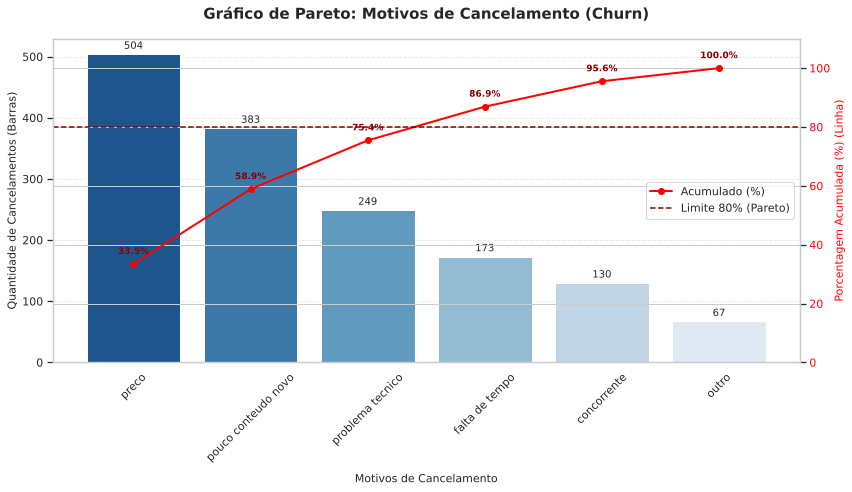

In [30]:
# 4. Plotagem do Gráfico de Pareto
fig, ax1 = plt.subplots(figsize=(12, 7))

# Gráfico de Barras para as Quantidades Absolutas (Eixo Y Esquerdo)
sns.barplot(
    data=tabela_pareto,
    x='Motivo de Cancelamento',
    y='Quantidade',
    ax=ax1,
    palette='Blues_r',
    hue='Motivo de Cancelamento',
    legend=False
)

ax1.set_title('Gráfico de Pareto: Motivos de Cancelamento (Churn)', fontsize=15, fontweight='bold', pad=20)
ax1.set_xlabel('Motivos de Cancelamento', fontsize=11, labelpad=10)
ax1.set_ylabel('Quantidade de Cancelamentos (Barras)', fontsize=11)
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Criar o segundo eixo Y compartilhando o mesmo eixo X para a porcentagem acumulada
ax2 = ax1.twinx()

# Plotar a Linha de Porcentagem Acumulada (Eixo Y Direito)
ax2.plot(
    tabela_pareto['Motivo de Cancelamento'],
    tabela_pareto['Porcentagem Acumulada (%)'],
    color='red',
    marker='o',
    markersize=6,
    linewidth=2,
    label='Acumulado (%)'
)

ax2.set_ylabel('Porcentagem Acumulada (%) (Linha)', fontsize=11, color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(0, 110)

# Adicionar linha horizontal de referência em 80%
ax2.axhline(y=80, color='darkred', linestyle='--', linewidth=1.5, label='Limite 80% (Pareto)')

# Adicionar rótulos percentuais nos pontos da linha acumulada
for i, valor in enumerate(tabela_pareto['Porcentagem Acumulada (%)']):
    ax2.annotate(
        f"{valor:.1f}%",
        (i, valor),
        textcoords="offset points",
        xytext=(0,10),
        ha='center',
        fontsize=9,
        color='darkred',
        fontweight='bold'
    )

# Adicionar valores absolutos em cima das barras
for p in ax1.patches:
    height = p.get_height()
    if not pd.isna(height):
        ax1.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=10,
            xytext=(0, 3),
            textcoords='offset points'
        )

# Legendas combinadas
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='center right')

plt.tight_layout()
plt.show()

> **Sua leitura do Pareto:**
>
> _Dois motivos concentram 59% dos cancelamentos. Os dois pedem a mesma ação, ou ações
> diferentes? Qual deles está sob controle do produto e qual é decisão comercial?
> E o cuidado do framework: um Pareto por quantidade e um por receita perdida
> apontariam os mesmos motivos?_

## Framework 4 — Funil de Onboarding

Nesta análise, mapeamos o comportamento do usuário ao longo da jornada de onboarding utilizando o dataset `funil_eventos.csv`. Tratamos as etapas para padronizar sua nomenclatura e calculamos a conversão relativa e acumulada para apontar qual etapa atua como o maior limitador (gargalo) do nosso funil.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregar o arquivo de eventos do funil
caminho_funil = f"{BASE_DADOS}/funil_eventos.csv"

try:
    df_funil = pd.read_csv(caminho_funil)
    print(f"Dataset carregado! Registros iniciais: {len(df_funil)}")

    # Remover duplicatas completas
    df_funil = df_funil.drop_duplicates()
    print(f"Registros após remoção de duplicatas: {len(df_funil)}")

    # Exibir primeiras linhas
    display(df_funil.head())
except FileNotFoundError:
    print(f"Não foi possível localizar o arquivo no caminho: {caminho_funil}")

Dataset carregado! Registros iniciais: 12886
Registros após remoção de duplicatas: 12836


,cliente_id,etapa
0,2165,assistiu_1a_aula
1,3269,criou_conta
2,4589,criou_conta
3,5228,visitou_site
4,4620,assistiu_1a_aula


In [32]:
# 2. Padronizar a escrita da coluna 'etapa'
if 'df_funil' in locals() and 'etapa' in df_funil.columns:
    # Colocar em minúsculo, remover espaços extras e substituir espaços internos por underscore
    df_funil['etapa'] = df_funil['etapa'].astype(str).str.lower().str.strip().str.replace(' ', '_')

    print("Etapas únicas encontradas após normalização:")
    print(df_funil['etapa'].value_counts())
else:
    print("Dataframe ou coluna 'etapa' ausente.")

Etapas únicas encontradas após normalização:
etapa
visitou_site        5000
criou_conta         3377
assistiu_1a_aula    2698
assinou_plano       1066
renovou              695
Name: count, dtype: int64


In [33]:
# 3. Montar a análise de conversão ordenada
ordem_funil = ['visitou_site', 'criou_conta', 'assistiu_1a_aula', 'assinou_plano', 'renovou']

if 'df_funil' in locals():
    # Contar usuários únicos por etapa do funil
    dados_etapas = []
    for etapa in ordem_funil:
        usuarios_unicos = df_funil[df_funil['etapa'] == etapa]['cliente_id'].nunique()
        dados_etapas.append({'Etapa': etapa, 'Usuarios_Unicos': usuarios_unicos})

    df_resultado_funil = pd.DataFrame(dados_etapas)

    # Calcular taxas de conversão
    total_topo = df_resultado_funil.loc[0, 'Usuarios_Unicos']

    df_resultado_funil['Conversao_Anterior (%)'] = 100.0
    df_resultado_funil['Conversao_Topo (%)'] = (df_resultado_funil['Usuarios_Unicos'] / total_topo) * 100.0

    for i in range(1, len(df_resultado_funil)):
        anterior = df_resultado_funil.loc[i-1, 'Usuarios_Unicos']
        atual = df_resultado_funil.loc[i, 'Usuarios_Unicos']
        if anterior > 0:
            df_resultado_funil.loc[i, 'Conversao_Anterior (%)'] = (atual / anterior) * 100.0
        else:
            df_resultado_funil.loc[i, 'Conversao_Anterior (%)'] = 0.0

    print("="*70)
    print(" TABELA DE CONVERSÃO DO FUNIL DE ONBOARDING ")
    print("="*70)
    display(df_resultado_funil)

 TABELA DE CONVERSÃO DO FUNIL DE ONBOARDING 


,Etapa,Usuarios_Unicos,Conversao_Anterior (%),Conversao_Topo (%)
0,visitou_site,5000,100.000000,100.00
1,criou_conta,3377,67.540000,67.54
2,assistiu_1a_aula,2698,79.893397,53.96
3,assinou_plano,1066,39.510749,21.32
4,renovou,695,65.196998,13.90


In [34]:
# 4. Identificar o maior gargalo (menor taxa de conversão em relação à etapa anterior, exceto a primeira)
if 'df_resultado_funil' in locals():
    # Pegamos apenas a partir do índice 1 (já que o topo do funil não tem etapa anterior)
    df_quedas = df_resultado_funil.iloc[1:].copy()

    # Gargalo é onde a taxa em relação à etapa anterior foi a menor
    idx_gargalo = df_quedas['Conversao_Anterior (%)'].idxmin()
    etapa_gargalo = df_resultado_funil.loc[idx_gargalo, 'Etapa']
    queda_pct = 100.0 - df_resultado_funil.loc[idx_gargalo, 'Conversao_Anterior (%)']

    print(f"O maior gargalo do funil está na transição para a etapa: '{etapa_gargalo.upper()}'")
    print(f"Apenas {df_resultado_funil.loc[idx_gargalo, 'Conversao_Anterior (%)']:.1f}% dos clientes da etapa anterior avançaram (uma perda de {queda_pct:.1f}%).")

O maior gargalo do funil está na transição para a etapa: 'ASSINOU_PLANO'
Apenas 39.5% dos clientes da etapa anterior avançaram (uma perda de 60.5%).


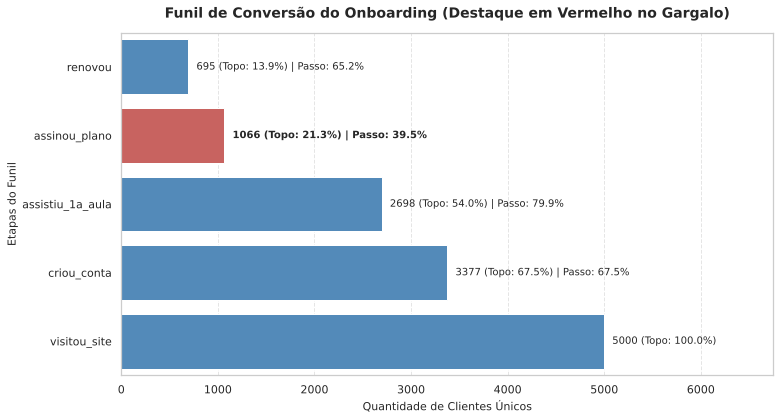

In [35]:
# 5. Plotagem gráfica do funil com destaque no gargalo (Versão Corrigida - Fluxo Descendente)
import matplotlib.pyplot as plt
import seaborn as sns

if 'df_resultado_funil' in locals() and 'etapa_gargalo' in locals():
    plt.figure(figsize=(11, 6))

    # Definir paleta de cores destacando apenas o gargalo
    cores = [
        '#d9534f' if row['Etapa'] == etapa_gargalo else '#428bca'
        for _, row in df_resultado_funil.iterrows()
    ]

    # Manter a ordem original para o topo (100%) aparecer na parte superior do gráfico
    df_plot = df_resultado_funil.copy()
    cores_plot = cores

    # Como o matplotlib plota a primeira linha na base e a última no topo por padrão para y categórico,
    # nós invertemos a ordem dos eixos do gráfico (invert_yaxis) para fixar o 'visitou_site' no topo real.
    ax = sns.barplot(
        data=df_plot,
        y='Etapa',
        x='Usuarios_Unicos',
        palette=cores_plot,
        hue='Etapa',
        legend=False
    )
    ax.invert_yaxis()  # Garante que o topo do funil (índice 0) fique na parte superior

    # Adicionar os rótulos de valores e taxas nas barras
    max_val = max(df_resultado_funil['Usuarios_Unicos'])
    for i, row in enumerate(df_plot.itertuples(index=False)):
        row_orig = df_plot.iloc[i]
        conversao_topo = row_orig['Conversao_Topo (%)']
        conversao_anterior = row_orig['Conversao_Anterior (%)']
        usuarios = row_orig['Usuarios_Unicos']
        etapa_atual = row_orig['Etapa']

        texto_label = f" {usuarios} (Topo: {conversao_topo:.1f}%)"
        if etapa_atual != 'visitou_site':
            texto_label += f" | Passo: {conversao_anterior:.1f}%"

        plt.text(
            usuarios + (max_val * 0.01),
            i,
            texto_label,
            va='center',
            fontsize=10,
            fontweight='bold' if etapa_atual == etapa_gargalo else 'normal'
        )

    plt.title('Funil de Conversão do Onboarding (Destaque em Vermelho no Gargalo)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Quantidade de Clientes Únicos', fontsize=11)
    plt.ylabel('Etapas do Funil', fontsize=11)
    plt.xlim(0, max_val * 1.35)
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

---
## Conclusões

### O que o dado tinha de errado

| Problema | Escala | Tratamento |
|---|---|---|
| Grafias inconsistentes em `plano` | 8 grafias para 3 planos | Padronização para minúsculas com acento |
| Grafias inconsistentes em `canal_aquisicao` | 9 grafias para 4 canais | Idem |
| Valor curinga `"?"` em `regiao` | 170 registros | Convertido para nulo |
| Erro de escala em `valor_mensal` | 596 registros (~12% da base) | Divisão por 100 — vírgula decimal perdida na exportação |
| Idades impossíveis | 13 registros (−2, 0, 1, 150, 300) | Removidos |
| Último acesso anterior à assinatura | 1 registro | Removido |
| Clientes duplicados | 25 `cliente_id` repetidos | Mantida a primeira ocorrência |

Os três tipos de outlier apareceram na mesma base: `valor_mensal` era **erro** de escala e
foi corrigido; as idades impossíveis eram **erro** e foram removidas; e os valores extremos
legítimos de `receita_acumulada` foram **mantidos**, porque descrevem clientes antigos reais.

### O que o dado respondeu, sem nenhum modelo

> **Sua conclusão de negócio:**
>
> _Escreva aqui, em três ou quatro frases, o que você recomendaria à diretoria. Use os
> números que o notebook produziu:_
>
> - _Pareto: preço (33,6%) e pouco conteúdo novo (25,4%) concentram 59% dos cancelamentos_
> - _Funil: a conversão para assinatura é de 39,5% — as etapas anteriores convertem 67% e 80%_
> - _Coorte: o que o heatmap mostra sobre as safras recentes comparadas às antigas_
> - _RFM: o tamanho do segmento "Em risco" entre os clientes ativos_
>
> _A pergunta que fecha: se a diretoria pudesse agir em uma só frente, qual seria e por quê?_

### Limitações

> **Sua avaliação:**
>
> _O que esta análise **não** permite concluir? Pense na diferença entre descrever,
> prever e explicar: o Pareto diz que preço é o motivo mais citado, mas isso prova que
> baixar o preço reduziria o churn? O que seria necessário para afirmar isso?_

### Próximos passos

> _O que você faria em seguida com esta base, e por quê._